## Setup
Run notebooks 01–07 first. Install dependencies once from the project root with `python -m pip install -r requirements.txt`.

In [11]:
from pathlib import Path
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate/"data").is_dir() and (candidate/"notebooks").is_dir(): PROJECT_ROOT=candidate; break
else: raise RuntimeError("Start Jupyter inside the project so its root can be found.")
DATA_DIR=PROJECT_ROOT/"data"; RAW_DATA_DIR=DATA_DIR/"01_raw"; INTERMEDIATE_DIR=DATA_DIR/"02_intermediate"
MODEL_DIR=PROJECT_ROOT/"models"; REPORT_DIR=PROJECT_ROOT/"reports"
INTERMEDIATE_DIR.mkdir(parents=True,exist_ok=True); MODEL_DIR.mkdir(parents=True,exist_ok=True); REPORT_DIR.mkdir(parents=True,exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\acer\Desktop\Programs\Projects_for _data_science\Fraud_Detection_Model


# 09 · Model explainability

This notebook explains global patterns and selected individual predictions with SHAP. Attributions describe how inputs move the model output relative to a chosen background. They do not establish causation, prove fraud, or explain information the model never received.

### SHAP installation (one time)

The project pins `shap==0.48.0` in `requirements.txt`. Install it into the **same Python environment as this notebook kernel** using `%pip install shap==0.48.0`, then restart the kernel. To install all project dependencies from the repository root, use `python -m pip install -r requirements.txt`. Do not run an install command every time you execute the notebook.


## 1. Load the model and validation rows

In [12]:
import joblib
import numpy as np
import pandas as pd
try:
    import shap
except ImportError as exc:
    raise ImportError("SHAP is missing from this notebook kernel. Run `%pip install shap==0.48.0`, then restart the kernel.") from exc

train_fe=pd.read_pickle(INTERMEDIATE_DIR/"train_features.pkl"); artifact=joblib.load(MODEL_DIR/"best_experiment_model.joblib")
features=list(artifact["feature_cols"]); ordered=train_fe.sort_values("TransactionDT",kind="stable").reset_index(drop=True)
val=ordered.iloc[int(len(ordered)*0.8):].copy(); X=val[features].replace([np.inf,-np.inf],np.nan)
if artifact.get("imputer") is not None: X=pd.DataFrame(artifact["imputer"].transform(X),columns=features,index=val.index)
if artifact.get("scaler") is not None: X=pd.DataFrame(artifact["scaler"].transform(X),columns=features,index=val.index)
model=artifact["model"]; print(type(model).__name__,X.shape)

XGBClassifier (118108, 420)


## 2. Build explanations on a fixed, bounded sample

The fixed seed makes the sample repeatable. A modest background and sample keep runtime manageable. The background population defines what “relative to typical” means in these plots.

For XGBoost, feature contributions come from XGBoost’s native TreeSHAP prediction output, which avoids SHAP’s compiled extension. Those values are in raw-margin (log-odds) space. Other supported classifiers use SHAP’s model-agnostic permutation explainer; it is slower, so the notebook limits its sample size.


In [13]:
import shap

# XGBoost can calculate TreeSHAP contributions itself. This avoids SHAP's
# compiled C extension, which may be blocked by Windows Application Control.
if type(model).__name__ == "XGBClassifier":
    SAMPLE_SIZE=min(500,len(X)); rng=np.random.default_rng(42)
    X_sample=X.iloc[rng.choice(len(X),size=SAMPLE_SIZE,replace=False)]
    import xgboost as xgb
    dmatrix=xgb.DMatrix(X_sample,feature_names=list(X_sample.columns))
    contributions=model.get_booster().predict(dmatrix,pred_contribs=True)
    # XGBoost returns one contribution per feature plus the bias term.
    explanation=shap.Explanation(
        values=contributions[:,:-1], base_values=contributions[:,-1],
        data=X_sample.to_numpy(), feature_names=list(X_sample.columns)
    )
    explainer_name="XGBoost native TreeSHAP (raw margin / log-odds)"
else:
    # Fallback for other estimators avoids the compiled TreeExplainer path.
    # Keep this sample small because model-agnostic permutation explanations cost more.
    SAMPLE_SIZE=min(25,len(X)); rng=np.random.default_rng(42)
    X_sample=X.iloc[rng.choice(len(X),size=SAMPLE_SIZE,replace=False)]
    background=X.iloc[[0]]
    if hasattr(model,"predict_proba"):
        explainer=shap.Explainer(model.predict_proba,background,algorithm="permutation")
        explanation=explainer(X_sample,max_evals=2*X_sample.shape[1]+1)
    else:
        raise TypeError(f"Model {type(model).__name__} has no supported prediction method for SHAP.")
    explainer_name="SHAP permutation explainer"
print(f"Explainer: {explainer_name} | output shape: {explanation.values.shape}")

Explainer: XGBoost native TreeSHAP (raw margin / log-odds) | output shape: (500, 420)


## 3. Global feature influence

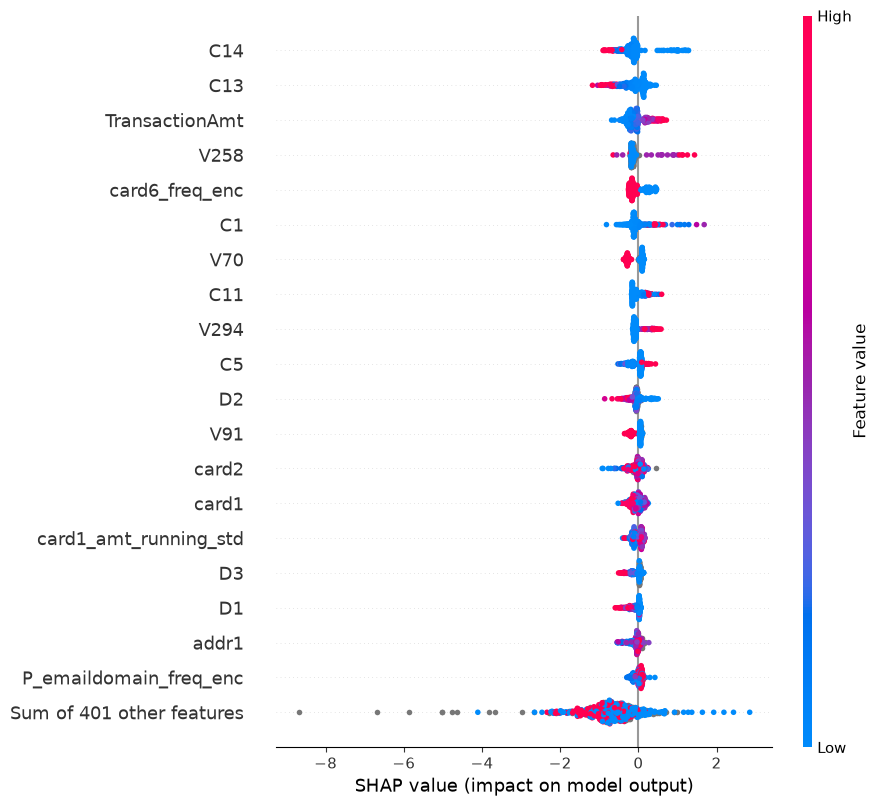

In [14]:
values=explanation
# Scikit-learn classifiers commonly return a final axis for both classes.
# Keep class 1 (fraud) so local contributions match the fraud output.
if values.values.ndim==3:
    positive_index=1
    raw_base=np.asarray(values.base_values)
    if raw_base.ndim==2:
        base=raw_base[:,positive_index]
    elif raw_base.ndim==1 and len(raw_base)>positive_index:
        base=raw_base[positive_index]
    else:
        base=raw_base
    values=shap.Explanation(
        values=values.values[:,:,positive_index], base_values=base,
        data=values.data, feature_names=values.feature_names
    )
shap.plots.beeswarm(values,max_display=20)

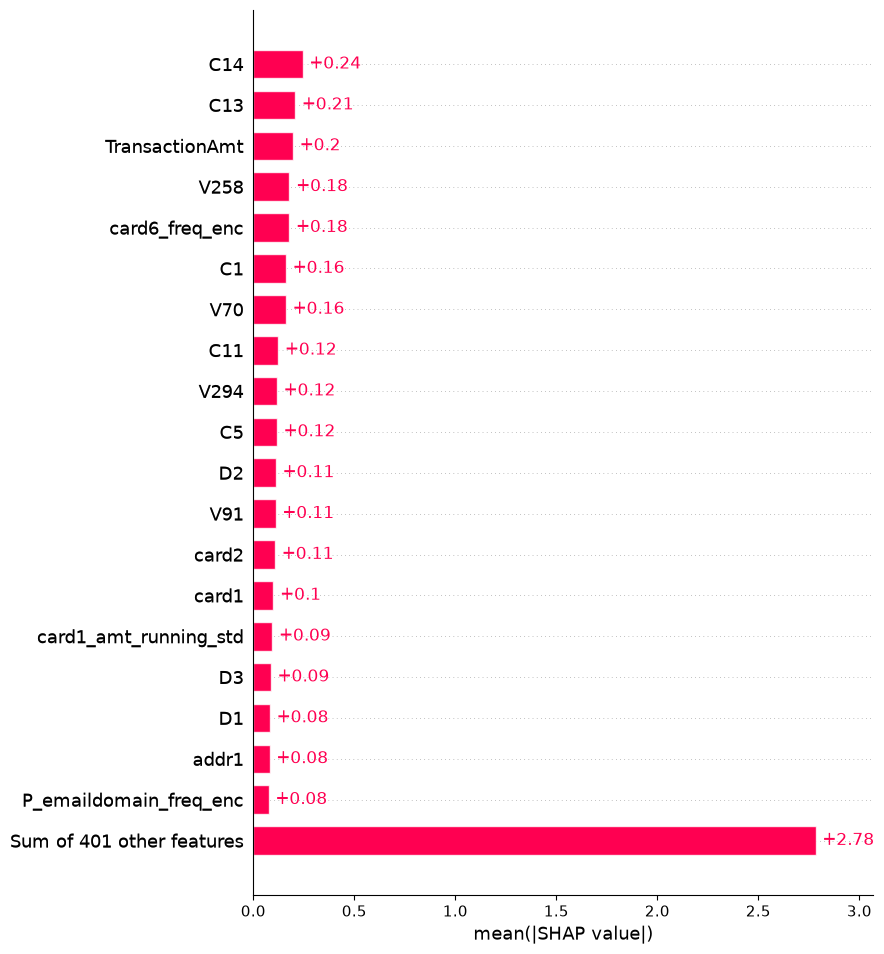

In [15]:
shap.plots.bar(values,max_display=20)

## 4. Explain one high-scoring example

For XGBoost the waterfall adds up to a raw margin (log-odds); the printed model probability is shown separately.


Model fraud probability: 0.9969


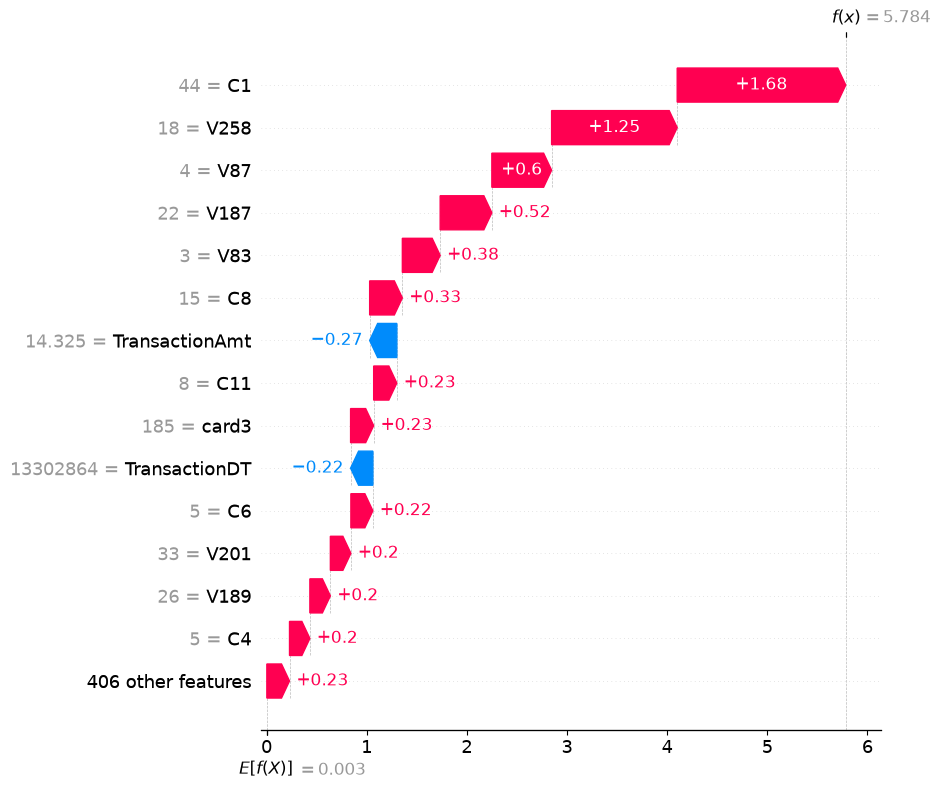

In [16]:
sample_prob=model.predict_proba(X_sample)[:,1]; local=int(np.argmax(sample_prob))
print(f"Model fraud probability: {sample_prob[local]:.4f}")
shap.plots.waterfall(values[local],max_display=15)


## 5. Review limits

Correlated inputs can share attributions. A strong feature may be a proxy or data-quality artifact, so verify its source and availability at decision time. Explanations support analyst review; they are not evidence by themselves. Record model version, explainer version, and reference population when operationalizing explanations.